# Analiza danych przestrzennych - ćwiczenia laboratoryjne 2025/2026

Ten notatnik zalicza się do grupy zestawów zadań, na podstawie których odbywa się zaliczenie ćwiczeń i podlega zwrotowi do oceny w ustalonym na zajęciach terminie.

Uwagi i wytyczne ogólne dotyczące uzupełniania i oceny notatnika:
- Podczas wykonywania zadań należy korzystać wyłącznie z pakietów zaimportowanych na początku notatnika oraz z pakietów wchodzących w skład standardowej biblioteki Pythona, które można zaimportować samodzielnie we wskazanej komórce notatnika.
- Swoje rozwiązania należy wprowadzać wyłącznie w miejce następujących fragmentów kodu:<br/> `# YOUR CODE HERE`<br/> `raise NotImplementedError()`<br/> 
a odpowiedzi tekstowe w komórkach oznaczonych hasłem:<br/> 
`YOUR ANSWER HERE`<br/> 
Nie należy w żaden sposób modyfikować pozostałych fragmentów kodu oraz innych elementów notatnika, w szczególności dodawać lub usuwać komórek oraz zmieniać nazwy pliku.
- Jeżeli zestaw zadań wymaga skorzystania z fragmentów kodu opracowanego w ramach wcześniejszych zestawów zadań należy je umieścić we wskazanej komórce notatnika.
- Otrzymywane wyniki i odpowiedzi mają być rezultatem wykonania napisanego kodu, odpowiedzi uzupełniane manualnie nie podlegają ocenie.
- Zawarte w notatniku automatyczne testy mają charakter poglądowy. Dotyczą one wybranych aspektów zadań i mają na celu wyłapać podstawowe błędy. Przejście przez kod wszystkich testów nie oznacza, że zadanie jest wykonane w całości poprawnie i zostanie ocenione na maksymalną liczbę punktów.
- Zadania należy wykonać w taki sposób, aby podczas wykonywania kodu nie zostały wyświetlone żadne ostrzeżenia.
- Zadania, które powodują wyświetlenie komunikatu o błędzie przerywającym wykonywanie kodu nie podlegają ocenie.
- W treści niektórych zadań mogą znaleźć się przykładowe schematy ich rozwiązania lub przykładowe schematy istotnych części rozwiązania. Nie zawsze są to rozwiązania optymalne pod kątem długości kodu lub prostoty rozwiązania.  Ich celem jest klarowne rozbicie pracy na kroki i ułatwienie samodzielnej weryfikacji wyników na każdym etapie. Należy je traktować wyłącznie poglądowo, a nie jako jedyne dopuszczalne rozwiązania. Ocenie podlega poprawność merytoryczna rozwiązania, jego kompletność oraz zgodność z wymaganiami, a nie konkretna forma zapisu.
- Dla zachowania przejrzystości i łatwego odnajdywania informacji w treści zadań podawane są pełne nazwy funkcji i klas wraz z nazwami pakietów (np. `pandas.read_csv()`, `geopandas.GeoDataFrame.to_crs`). W notatniku te same obiekty są dostępne przez skrótowe aliasy (np. `pd.read_csv()`, `gpd.GeoDataFrame.to_crs`).

Uwagi i wytyczne ogólne dotyczące wizualizacji wyników:
- Wszystkie wykresy powinny być wykonane w jednolitym, przejrzystym i czytelnym stylu, posiadać odpowiednio dobrane proporcje i zakresy wartości osi.
- Figury powinny mieć ustawione białe tło, tak, aby niezależnie od ustawień notatnika wszystkie elementy wykresów były dobrze widoczne (domyślnie tło jest przeźroczyste co może powodować problemy w notatnikach z ustawionym ciemnym tłem). Rozmiar poziomy figur nie powinien przekraczać 20 cali.
- Wykresy oraz ich osie powinny mieć nadane tytuły. Jeżeli w obrębie figury znajduje się więcej niż jeden wykres to figura również powinna mieć nadany tytuł.

Przed odesłaniem zestawu zadań do oceny proszę uzupełnić komórkę z danymi autorów rozwiązania (nazwa zespołu oraz imiona, nazwiska i numery indeksów członków zespołu) oraz upewnić się, że notatnik działa zgodnie z oczekiwaniami. W tym celu należy skorzystać z opcji **Restart Kernel and Run All Cells...** dostępnej na górnej belce notatnika pod symbolem $\blacktriangleright\blacktriangleright$.

Nazwa zespołu: GIN12  
Członkowie:  
Michał Kuśnierz 426683,  
Tymoteusz Chrzan 426173,  
Tymoteusz Hajduk 428250

---

## Zestaw zadań 10: Klasteryzacja i autokorelacja przestrzennna danych

In [1]:
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import contextily as cx

from pysal.lib import weights
from pysal.explore import esda

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, HDBSCAN
from matplotlib.colors import ListedColormap, BoundaryNorm

C:\Users\student\Desktop\Python ADP\.venv\Lib\site-packages\spaghetti\network.py:41: FutureWarning: The next major release of pysal/spaghetti (2.0.0) will drop support for all ``libpysal.cg`` geometries. This change is a first step in refactoring ``spaghetti`` that is expected to result in dramatically reduced runtimes for network instantiation and operations. Users currently requiring network and point pattern input as ``libpysal.cg`` geometries should prepare for this simply by converting to ``shapely`` geometries.
  warnings.warn(dep_msg, FutureWarning, stacklevel=1)


In [2]:
# Miejsce do importu pakietów wchodzących w skład standardowej biblioteki Pythona oraz ustawienie opcji wykorzystywanych pakietów

### Wczytanie danych
Poniższy kod wczytuje do zmiennych `city`, `healthcare`, `sweden_data` oraz `districts_data` dane z pliku data.gpkg.

In [3]:
city = gpd.read_file("data.gpkg", layer='city')
city

,Nazwa,geometry
0,Kraków,"POLYGON ((571937.571 237575.079, 571934.41 237..."


In [5]:
healthcare = gpd.read_file("data.gpkg", layer='healthcare')
healthcare.head()

,geometry
0,POINT (567648.626 242679.161)
1,POINT (565324.881 245360.641)
2,POINT (571657.083 238891.309)
3,POINT (575026.424 244689.629)
4,POINT (576415.591 246533.94)


In [6]:
sweden_data = gpd.read_file("data.gpkg", layer='sweden_data')
sweden_data.head()

,Nazwa,geometry
0,Skåne län,"MULTIPOLYGON (((4578466.673 3717657.885, 45792..."
1,Blekinge län,"MULTIPOLYGON (((4696473.483 3703084.086, 46963..."
2,Kronobergs län,"MULTIPOLYGON (((4632645.506 3802767.507, 46331..."
3,Hallands län,"MULTIPOLYGON (((4460469.928 3829549.031, 44604..."
4,Västra Götalands län,"MULTIPOLYGON (((4448860.421 4019224.4, 4449098..."


In [7]:
districts_data = gpd.read_file("data.gpkg", layer='districts_data')
districts_data.head()

,Nazwa,Czytelnicy bibliotek (2023),Nowe mieszkania na 10tyś mieszkańców (2023),Gęstość zaludnienia (2023),Wskaźnik obciążenia demograficznego (2023),Przyrost naturalny (2023),Lesistość (2023),Saldo migracji (2023),Ludność w wieku przedprodukcyjnym (2023),Ludność w wieku produkcyjnym (2023),Ludność w wieku poprodukcyjnym (2023),geometry
0,powiat bolesławiecki,115.0,45.2,67.2,71.5,-3.85,59.2,0.3,17.8,58.3,23.9,"MULTIPOLYGON (((278695.74 398348.843, 278695.6..."
1,powiat dzierżoniowski,108.0,39.8,198.0,76.2,-9.53,20.6,-1.9,15.6,56.8,27.7,"MULTIPOLYGON (((346955.102 313769.706, 346846...."
2,powiat głogowski,93.0,24.4,191.9,76.4,-4.39,22.2,-3.4,18.0,56.7,25.4,"MULTIPOLYGON (((298734.283 417178.027, 298745...."
3,powiat górowski,110.0,22.1,44.0,71.4,-5.81,28.7,-3.7,17.5,58.3,24.1,"MULTIPOLYGON (((337018.116 424268.419, 337046...."
4,powiat jaworski,107.0,30.0,81.2,74.2,-6.52,22.0,-2.4,16.8,57.4,25.8,"MULTIPOLYGON (((303741.051 350450.818, 303749...."


### Funkcje wykorzystywane w komórkach testowych

In [8]:
def custom_cmap(max_label, noise_color="#d9d9d9"):
    tab20 = plt.get_cmap("Paired")
    hsv = plt.get_cmap("hsv")

    colors = [noise_color]

    for i in range(max_label + 1):
        if i < tab20.N:
            colors.append(tab20(i))
        else:
            colors.append(hsv((i - tab20.N) / (max_label - tab20.N + 1)))

    cmap = ListedColormap(colors)
    norm = BoundaryNorm(
        boundaries=np.arange(-1.5, max_label + 1.5, 1),
        ncolors=cmap.N
    )
    return cmap, norm

cmap, norm = custom_cmap(20)

### Zadanie 1: Klasteryzacja danych przestrzennych [12 pkt]

Zmienna `healthcare` zawiera zbiór danych punktowych reprezentujących lokalizacje obiektów ochrony zdrowia (szpitale, przychodnie, apteki itp.) na terenie Krakowa. Zbiór ten zawiera struktury o zróżnicowanym charakterze przestrzennym, w szczególności klastry o zróżnicowanej wielkości, kształcie i gęstości oraz obserwacje odstające (szum).

#### a) Przeprowadzenie klasteryzacji

Wykonaj klasteryzację tego zbioru danych przy użyciu czterech różnych metod:
- k-średnich `sklearn.cluster.KMeans()`,
- klasteryzacja hierarchiczna `sklearn.cluster.AgglomerativeClustering()`,
- DBSCAN `sklearn.cluster.DBSCAN()`,
- HDBSCAN `sklearn.cluster.HDBSCAN()`,

Dla każdej metody dobierz wartości parametrów w sposób uzasadniony charakterem danych i możliwościami danej metody tak, aby uzyskać możliwie najlepszy wynik. Zwróć jednak uwagę, że nie każda metoda klasteryzacji jest w stanie uzyskać dla tego zestawu danych w pełni satysfakcjonujący wynik.

Algorytm postępowania:
1. Korzystając z własności `geopandas.GeoDataFrame.geometry.x` i `geopandas.GeoDataFrame.geometry.y` wyodrębnij z geometrii rozkładu współrzędne X i Y poszczególnych punktów. Następnie korzystajac z `numpy.vstack()` lub `numpy.concatenate()` oraz transpozycji skonstruuj macierz współrzędnych o wymiarach `(n, 2)`, gdzie n to liczba punktów rozkładu.
2. Korzystając z wymienionych wyżej klas oraz przynależnych do nich funkcji `fit_predict()` (np. `sklearn.cluster.KMeans.fit_predict()`) dokonaj klasteryzacji zestawu danych. Każdorazowo dobierz wartości parametrów w sposób uzasadniony charakterem danych i możliwościami danej metody tak, aby uzyskać możliwie najlepszy wynik. Na tym etapie rozważ następujące parametry (niebędne minimum):
    - k-średnich: `n_clusters`;
    - klasteryzacja hierarchiczna: , `linkage`, `n_clusters` lub `distance_threshold` (dwa ostatnie stosowane zamiennie);
    - DBSCAN: `eps`, `min_samples`;
    - HDBSCAN: `min_cluster_size`, `min_samples`, `cluster_selection_epsilon`, `max_cluster_size`;
4. Zapisz wynik klasteryzacji do kolumny tablicy `healthcare` o odpowiedniej nazwie (KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN).

In [83]:
X = np.vstack((healthcare.geometry.x.values, healthcare.geometry.y.values)).T

healthcare["KMeans"] = KMeans(
    n_clusters=14,
    random_state=42,
    n_init=25).fit_predict(X)

healthcare["AgglomerativeClustering"] = AgglomerativeClustering(
    n_clusters=14,
    linkage="complete").fit_predict(X)

healthcare["DBSCAN"] = DBSCAN(
    eps=600,
    min_samples=10).fit_predict(X)

healthcare["HDBSCAN"] = HDBSCAN(
    min_cluster_size=10,
    min_samples=8,
    cluster_selection_epsilon=600).fit_predict(X)

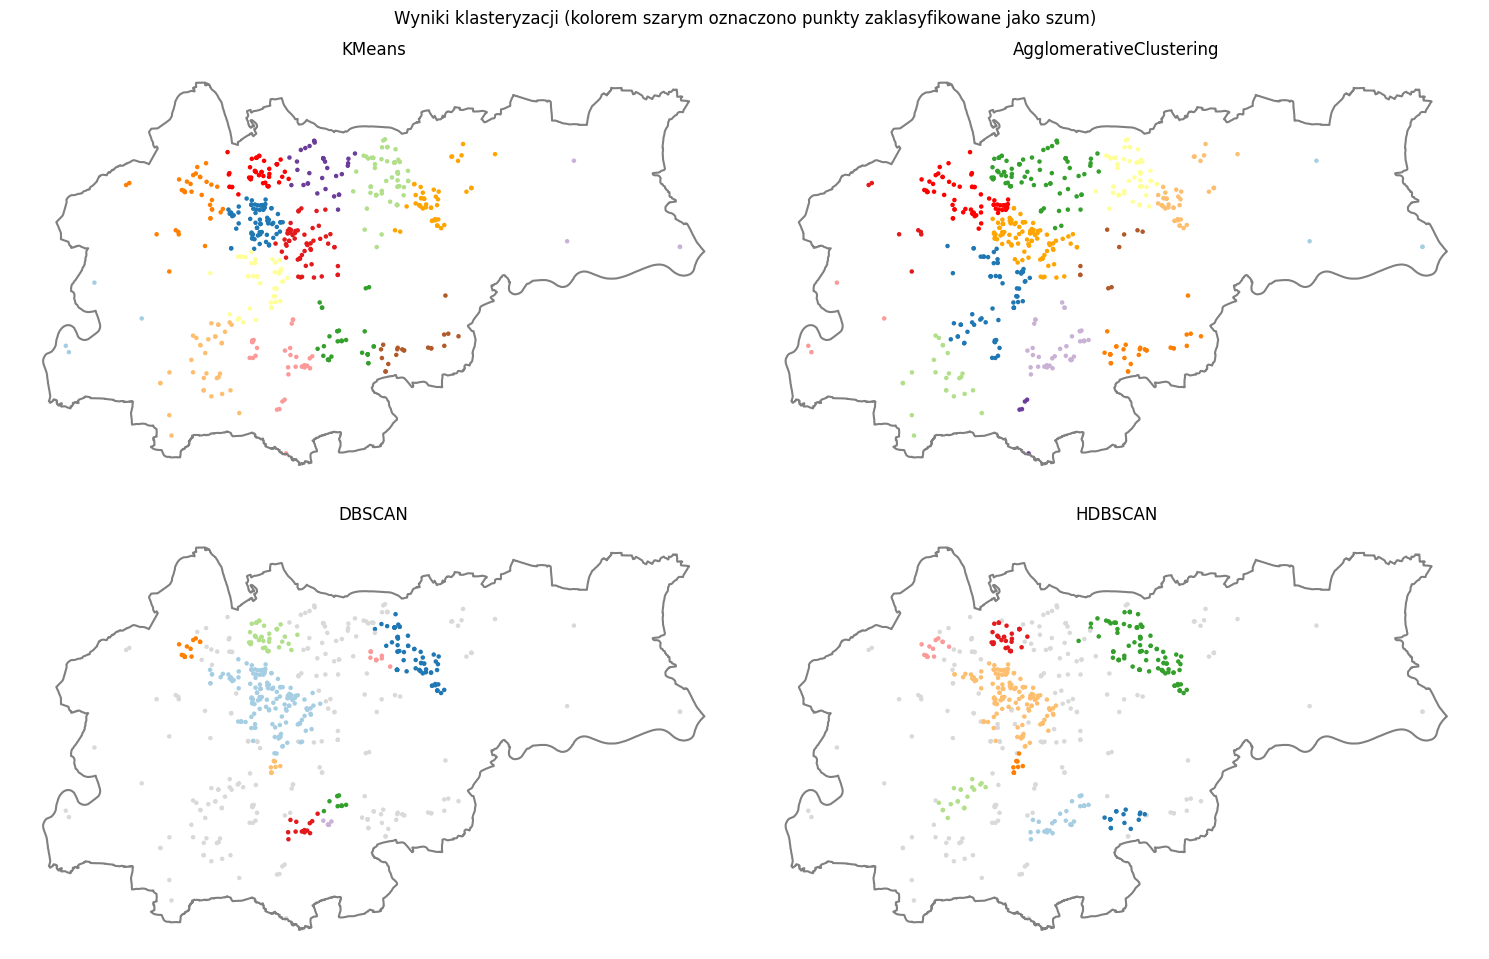

In [84]:
# Komórka testowa 
columns = ['KMeans', 'AgglomerativeClustering', 'DBSCAN', 'HDBSCAN']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

fig.suptitle("Wyniki klasteryzacji (kolorem szarym oznaczono punkty zaklasyfikowane jako szum)")

for i, ax in enumerate(axes.flat):
    ax.set_title(columns[i])    
    city.boundary.plot(ax=ax, color="grey")
    ax.set_axis_off()
    try:
        healthcare.plot(ax=ax, column=columns[i], cmap=cmap, norm=norm, markersize=5, legend=False)
    except:
        pass

plt.tight_layout()
assert type(healthcare) == gpd.GeoDataFrame
assert healthcare.shape == (542, 5)
assert set(healthcare.columns) == set(['geometry', 'KMeans', 'AgglomerativeClustering', 'DBSCAN', 'HDBSCAN'])
assert np.all(np.isclose(healthcare[['KMeans', 'AgglomerativeClustering', 'DBSCAN', 'HDBSCAN']].min().values, np.array([ 0,  0, -1, -1])))

#### b) Uzasadnienie i ocena wyników

Krótko (kilka zdań dla każdej metody):
 - Uzasadnij dobór parametrów z punktu widzenia charakteru danych przestrzennych oraz założeń i ograniczeń danej metody klasteryzacji.
 - Oceń jakość otrzymanego wyniku:
     - czy metoda poprawnie identyfikuje klastry o różnej wielkości, gęstości i kształcie,
     - czy potrafi wykryć szum,
     - czy przyjęte założenia (np. liczba klastrów) są realistyczne w tym problemie,
     - itd.

<div style="color: limegreen;">

### KMeans

- **Dobór parametrów i założenia metody:**  
  Metoda wymaga z góry zadanej liczby klastrów oraz zakłada, że mają one kształt zbliżony do kulistego i porównywalne rozmiary. Na wykresie widać, że dane przestrzenne mają nieregularną strukturę i zróżnicowaną gęstość, co stoi w sprzeczności z tymi założeniami.

- **Czy metoda poprawnie identyfikuje klastry o różnej wielkości, gęstości i kształcie:**  
  **Nie** – widoczne są sztuczne podziały obszarów o ciągłej strukturze oraz łączenie punktów, które naturalnie nie tworzą jednego skupienia.

- **Czy potrafi wykryć szum:**  
  **Nie** – wszystkie punkty zostały przypisane do klastrów, w tym również obserwacje wyraźnie odstające.

- **Czy przyjęte założenia są realistyczne:**  
  **Nie** – narzucona liczba klastrów oraz uproszczone założenia geometryczne nie odpowiadają rzeczywistej strukturze danych przestrzennych.

### Agglomerative Clustering

- **Dobór parametrów i założenia metody:**  
  Metoda hierarchiczna nie wymaga inicjalizacji centrów, ale wymaga ustalenia liczby klastrów lub progu odległości. Wynik silnie zależy od doboru metryki i sposobu łączenia (linkage).

- **Czy metoda poprawnie identyfikuje klastry o różnej wielkości, gęstości i kształcie:**  
  **Częściowo** – na wykresie widać, że metoda potrafi tworzyć bardziej nieregularne klastry niż KMeans, jednak nadal łączy obszary o różnej gęstości w jeden klaster.

- **Czy potrafi wykryć szum:**  
  **Nie** – podobnie jak KMeans, przypisuje wszystkie punkty do klastrów, także te wyraźnie odstające.

- **Czy przyjęte założenia są realistyczne:**  
  **Nie** – konieczność narzucenia liczby klastrów nie odzwierciedla naturalnej, złożonej struktury danych widocznej na mapie.

### DBSCAN

- **Dobór parametrów i założenia metody:**  
  Metoda oparta na gęstości, co czyni ją odpowiednią dla danych przestrzennych. Parametry `eps` i `min_samples` definiują, czym jest obszar gęsty.

- **Czy metoda poprawnie identyfikuje klastry o różnej wielkości, gęstości i kształcie:**  
  **Częściowo** – na wykresie widoczne są klastry o nieregularnych kształtach, co jest zgodne z założeniami metody. Jednak część mniejszych lub rzadszych skupień została zaklasyfikowana jako szum.

- **Czy potrafi wykryć szum:**  
  **Tak** – punkty odstające są wyraźnie oznaczone kolorem szarym.

- **Czy przyjęte założenia są realistyczne:**  
  **Częściowo** – jeden globalny zestaw parametrów nie radzi sobie dobrze z obszarami o różnej lokalnej gęstości, co widać w postaci nadmiernej liczby punktów zaklasyfikowanych jako szum.

### HDBSCAN

- **Dobór parametrów i założenia metody:**  
  Metoda rozszerza DBSCAN, automatycznie dostosowując się do lokalnych zmian gęstości i nie wymagając podania liczby klastrów z góry.

- **Czy metoda poprawnie identyfikuje klastry o różnej wielkości, gęstości i kształcie:**  
  **Tak** – na wykresie widoczne są klastry o zróżnicowanych kształtach i rozmiarach, które odpowiadają naturalnym skupieniom punktów.

- **Czy potrafi wykryć szum:**  
  **Tak** – punkty odstające są wyraźnie oddzielone od struktur klastrowych.

- **Czy przyjęte założenia są realistyczne:**  
  **Tak** – metoda najlepiej odpowiada charakterowi danych przestrzennych, w których występują skupienia o zmiennej gęstości i nieregularnych kształtach.

### Podsumowanie

Na podstawie wizualnej analizy wyników można stwierdzić, że **HDBSCAN** najlepiej odwzorowuje naturalną strukturę danych: poprawnie rozpoznaje klastry o różnych kształtach i gęstościach oraz skutecznie identyfikuje szum.  
**DBSCAN** również dobrze radzi sobie z nieregularnymi strukturami, lecz jest wrażliwy na dobór parametrów.  
Metody **KMeans** i **Agglomerative Clustering** wypadają słabiej, ponieważ narzucają sztuczną strukturę klastrów i nie potrafią wykrywać punktów odstających.

</div>


### Zadanie 2: Macierz wag przestrzannych [7 pkt]

Zmienna `sweden_data` zawiera dane przedstawiające podział administracyjny Szwecji.

#### a) Generowanie macierzy wag przestrzennych

Utwórz trzy macierze wag przestrzennych za pomocą trzech metod:
1) `pysal.lib.weights.contiguity.Rook.from_dataframe()`;
2) `pysal.lib.weights.distance.KNN.from_dataframe()` przyporządkowując do każdego z obszarów 4 najbliższych sąsiadów;
3) `pysal.lib.weights.distance.DistanceBand.from_dataframe()` przyporządkowując do każdego z obszarów sąsiadów w promieniu 300km (liczone między centroidami obszarów).

Korzystając z powyższych funkcji każdorazowo ustaw argument `use_index=True`.
Zapisz wyniki do zmiennych `w_r`, `w_knn` i `w_db` oraz wyświetl liczbę sąsiadów poszczególnych obszarów korzystając z własności `cardinalities` (np. `weights.contiguity.Rook.cardinalities`). 

Uwaga! W przypadku, gdy algorytm ze względu na swoje ograniczenia lub dobór parametrów nie był w stanie dopasować sąsiadów do wszystkich obszarów wyświetlony zostanie komunikat `UserWarning: The weights matrix is not fully connected`. Nie należy się nim w takiej sytuacji przejmować.

In [11]:
w_r = weights.contiguity.Rook.from_dataframe(sweden_data, use_index=True)
w_r.cardinalities

C:\Users\student\Desktop\Python ADP\.venv\Lib\site-packages\libpysal\weights\contiguity.py:61: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 7.
  W.__init__(self, neighbors, ids=ids, **kw)


{0: 3,
 1: 3,
 2: 5,
 3: 4,
 4: 5,
 5: 3,
 6: 4,
 7: 0,
 8: 5,
 9: 1,
 10: 2,
 11: 4,
 12: 4,
 13: 4,
 14: 3,
 15: 3,
 16: 5,
 17: 5,
 18: 6,
 19: 5,
 20: 4}

In [12]:
w_knn = weights.distance.KNN.from_dataframe(sweden_data, k=4, use_index=True)
w_knn.cardinalities

{0: 4,
 1: 4,
 2: 4,
 3: 4,
 4: 4,
 5: 4,
 6: 4,
 7: 4,
 8: 4,
 9: 4,
 10: 4,
 11: 4,
 12: 4,
 13: 4,
 14: 4,
 15: 4,
 16: 4,
 17: 4,
 18: 4,
 19: 4,
 20: 4}

In [14]:
w_db = weights.distance.DistanceBand.from_dataframe(
    sweden_data,
    threshold=300000,
    binary=True,
    use_index=True)

w_db.cardinalities

{0: 7,
 1: 8,
 2: 10,
 3: 8,
 4: 11,
 5: 10,
 6: 12,
 7: 10,
 8: 13,
 9: 1,
 10: 10,
 11: 12,
 12: 9,
 13: 9,
 14: 4,
 15: 3,
 16: 12,
 17: 15,
 18: 14,
 19: 10,
 20: 4}

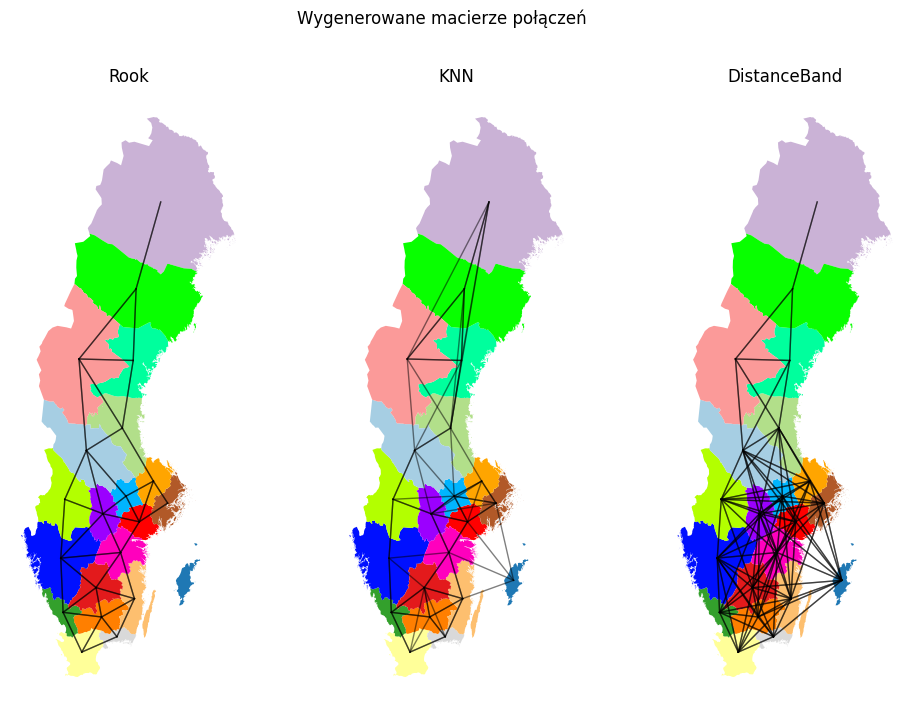

In [15]:
# Komórka testowa
fig, axes = plt.subplots(1, 3, figsize=(12, 8))

fig.suptitle("Wygenerowane macierze połączeń")

titles = ["Rook", "KNN", "DistanceBand"]
for i, ax in enumerate(axes.flat):
    ax.set_title(titles[i])    
    sweden_data.plot(ax=ax, column="Nazwa", cmap=cmap)
    ax.set_axis_off()

try:
    w_r.plot(sweden_data, ax=axes[0], edge_kws=dict(color='black', linewidth=1, alpha=0.5), node_kws=dict(marker=''))
except:
    pass

try:
    w_knn.plot(sweden_data, ax=axes[1], edge_kws=dict(color='black', linewidth=1, alpha=0.5), node_kws=dict(marker=''))
except:
    pass
    
try:
    w_db.plot(sweden_data, ax=axes[2], edge_kws=dict(color='black', linewidth=1, alpha=0.5), node_kws=dict(marker=''))
except:
    pass

assert type(w_r) == weights.contiguity.Rook
assert len(w_r.cardinalities) == 21
assert np.all(np.isclose(np.array(list(w_r.cardinalities.values())), np.array([3, 3, 5, 4, 5, 3, 4, 0, 5, 1, 2, 4, 4, 4, 3, 3, 5, 5, 6, 5, 4])))

assert type(w_knn) == weights.distance.KNN
assert len(w_knn.cardinalities) == 21
assert np.all(np.isclose(np.array(list(w_knn.cardinalities.values())), np.array([4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4])))

assert type(w_db) == weights.distance.DistanceBand
assert len(w_db.cardinalities) == 21
assert np.all(np.isclose(np.array(list(w_db.cardinalities.values())), np.array([7,  8, 10,  8, 11, 10, 12, 10, 13,  1, 10, 12,  9,  9,  4,  3, 12, 15, 14, 10,  4])))

#### b) Analiza wyników

Krótko (kilka zdań dla każdej metody) oceń wygenerowane macierze wag przestrzennych. Odpowiedz jak poszczególne metody poradziły sobie z układem granic, obszarami przestrzennie izolowanymi oraz z różną wielkościa obszarów (duże jednostki na północy, mniejsze na południu).

Podczas oceny macierzy zwróć uwagę na fakt, że linie na grafice wygenerowanej w komórce testowej są półprzeźroczyste - w ziwązku z tym czarna linia oznacza, że obszary są wzajemnie swoimi sąsiadami, a linia szara, że relacja jest jednokierunkowa.

<div style="color: limegreen;">

### Rook
Macierz wag oparta na sąsiedztwie typu *rook* bardzo dobrze odwzorowuje rzeczywisty układ granic administracyjnych – relacje sąsiedztwa występują wyłącznie tam, gdzie jednostki faktycznie dzielą wspólną granicę. Dzięki temu struktura połączeń jest zgodna z topologią przestrzeni i nie generuje sztucznych relacji między odległymi obszarami. Metoda ta dobrze radzi sobie z jednostkami o zróżnicowanej wielkości, jednak w przypadku obszarów przestrzennie izolowanych (np. wysp lub jednostek oddzielonych akwenami) może prowadzić do ich całkowitej izolacji w macierzy wag. Widoczne są również relacje jednokierunkowe (szare linie), wynikające z nieregularnych kształtów jednostek i asymetrii ich połączeń.

### KNN
Macierz KNN zapewnia, że każda jednostka ma dokładnie określoną liczbę sąsiadów, co eliminuje problem izolowanych obszarów. Z punktu widzenia spójności grafu jest to zaleta, jednak metoda ta całkowicie ignoruje rzeczywisty przebieg granic administracyjnych. W rezultacie powstają relacje pomiędzy jednostkami, które w rzeczywistości nie stykają się ze sobą. Efekt ten jest szczególnie widoczny w północnej części kraju, gdzie duże jednostki są łączone z odległymi sąsiadami. Na południu, gdzie jednostki są mniejsze i gęściej rozmieszczone, sieć połączeń staje się bardzo gęsta, co skutkuje dużą liczbą relacji jednokierunkowych (linie szare) i mniejszą czytelnością struktury przestrzennej.

### DistanceBand
Macierz typu *DistanceBand* dobrze oddaje lokalne relacje przestrzenne w obszarach o dużej gęstości jednostek, co jest wyraźnie widoczne w południowej części kraju. W tych regionach wiele jednostek mieści się w zadanym promieniu, co prowadzi do powstania gęstej sieci połączeń. Natomiast na północy, gdzie jednostki są duże i silnie rozproszone, część obszarów ma niewielu sąsiadów lub pozostaje całkowicie izolowana. Metoda jest silnie wrażliwa na dobór promienia – zbyt mała wartość prowadzi do fragmentacji grafu, natomiast zbyt duża może generować nadmiar relacji. Widoczne relacje jednokierunkowe wynikają z asymetrii położeń centroidów względem zadanego progu odległości.

</div>


### Zadanie 3: Autokorelacja przestrzenna danych [6 pkt]

Zmienna `districts_data` zawieraja geometrie powiatów oraz przypisane do nich statystyki.

### a) Obliczenie statystyk

Oblicz wartości statystyk Morana I oraz Geary’ego C dla dwóch zmiennych: salda migracji i przyrostu naturalnego.

Algorytm postępowania:
1) Korzystając z `pysal.lib.weights.contiguity.Rook.from_dataframe()` oblicz i zapisz do zmiennej `w` macierz wag przestrzennych.
2) Dla każdej ze statystyk:
     - korzystając z `pysal.explore.esda.moran.Moran()` wygeneruj obiekt zawierający wyniki obliczeń statystyki Morana;
     - korzystając z `pysal.explore.esda.geary.Geary()` wygeneruj obiekt zawierający wyniki obliczeń statystyki Geary’ego;

    Zapisz wyniki do zmiennych `moran_sm` i `geary_sm` (saldo migracji) oraz `moran_pn` i `moran_pn` (przyrost naturalny).
4) Zapisz do zmiennych oraz odpowiednich własności wygenerowanych obiektów:
    - wartość statystyki I: `pysal.explore.esda.moran.Moran.I`
    - wartość statystki C: `pysal.explore.esda.geary.Geary.C`
    - p-value: `pysal.explore.esda.moran.Moran.p_sim` oraz `pysal.explore.esda.geary.Geary.p_sim`
5) Wyświetl wyniki analiz za pomocą funkcji `print()` 

In [25]:
w = weights.contiguity.Rook.from_dataframe(districts_data, use_index=True)

In [28]:
moran_I_sm = esda.Moran(districts_data["Saldo migracji (2023)"].values, w).I
moran_p_sm = esda.Moran(districts_data["Saldo migracji (2023)"].values, w).p_sim
geary_C_sm = esda.Geary(districts_data["Saldo migracji (2023)"].values, w).C
geary_p_sm = esda.Geary(districts_data["Saldo migracji (2023)"].values, w).p_sim

print("Saldo migracji – Moran I:", moran_I_sm)
print("Saldo migracji – Moran p-value:", moran_p_sm)
print("Saldo migracji – Geary C:", geary_C_sm)
print("Saldo migracji – Geary p-value:", geary_p_sm)

Saldo migracji – Moran I: 0.17418861971191557
Saldo migracji – Moran p-value: 0.001
Saldo migracji – Geary C: 0.9319430884750145
Saldo migracji – Geary p-value: 0.095


In [29]:
# Komórka testowa
assert np.isclose(moran_I_sm, 0.17418861971191557)
assert np.isclose(moran_p_sm, 0.001)
assert np.isclose(geary_C_sm, 0.9319430884750145)
assert geary_p_sm>0.05

In [30]:
moran_obj_pn = esda.Moran(districts_data["Przyrost naturalny (2023)"].values, w)
geary_obj_pn = esda.Geary(districts_data["Przyrost naturalny (2023)"].values, w)

moran_I_pn = moran_obj_pn.I
moran_p_pn = moran_obj_pn.p_sim
geary_C_pn = geary_obj_pn.C
geary_p_pn = geary_obj_pn.p_sim

print("Przyrost naturalny – Moran I:", moran_I_pn)
print("Przyrost naturalny – Moran p-value:", moran_p_pn)
print("Przyrost naturalny – Geary C:", geary_C_pn)
print("Przyrost naturalny – Geary p-value:", geary_p_pn)

Przyrost naturalny – Moran I: 0.4847877317074219
Przyrost naturalny – Moran p-value: 0.001
Przyrost naturalny – Geary C: 0.5167537072706061
Przyrost naturalny – Geary p-value: 0.001


In [31]:
# Komórka testowa
assert np.isclose(moran_I_pn, 0.484787731707421)
assert np.isclose(moran_p_pn, 0.001)
assert np.isclose(geary_C_pn, 0.5167537072706061)
assert np.isclose(geary_p_pn, 0.001)

#### b) Interpretacja wyników

Na podstawie uzyskanych wyników oceń, czy dla badanych zmiennych występuje istotna globalna autokorelacja przestrzenna oraz porównaj zachowanie statystyk Morana I i Geary’ego C. Interpretacja powinna uwzględniać znak i wartość statystyki Morana I, relację wartości statystyki Geary’ego C do 1 oraz poziomy istotności statystycznej. Podczas interpretacji przyjmij poziom istotności alpha=0.05.

<div style="color: limegreen;">

#### Saldo migracji (2023)

- **Moran I = 0.174** – dodatnia, lecz niewielka wartość wskazuje na słabą dodatnią autokorelację przestrzenną, czyli tendencję do grupowania się powiatów o podobnych wartościach salda migracji.  
- **Geary C = 0.932** – wartość mniejsza od 1 również sugeruje dodatnią autokorelację, jednak bliskość do 1 oznacza, że efekt jest słaby.  
- **Istotność statystyczna:**  
  - Moran: p = 0.001 < 0.05 → wynik istotny statystycznie  
  - Geary: p = 0.095 > 0.05 → wynik nieistotny statystycznie  

**Wniosek:**  
Saldo migracji wykazuje **słabą, lecz statystycznie istotną dodatnią autokorelację przestrzenną** według statystyki Morana I. Brak istotności testu Geary’ego C sugeruje, że efekt ten nie jest wyraźny na poziomie lokalnych różnic pomiędzy sąsiadami, lecz raczej ma charakter bardziej globalny.

#### Przyrost naturalny (2023)

- **Moran I = 0.485** – wyraźnie dodatnia wartość wskazuje na **silną dodatnią autokorelację przestrzenną**, czyli wyraźne grupowanie się powiatów o podobnych wartościach przyrostu naturalnego.  
- **Geary C = 0.517** – wartość znacznie mniejsza od 1 potwierdza silną dodatnią autokorelację.  
- **Istotność statystyczna:**  
  - Moran: p = 0.001 < 0.05  
  - Geary: p = 0.001 < 0.05  

**Wniosek:**  
Przyrost naturalny wykazuje **silną i statystycznie istotną dodatnią autokorelację przestrzenną**. Obie statystyki są ze sobą zgodne, co oznacza, że podobne wartości tej zmiennej wyraźnie grupują się przestrzennie.

#### Porównanie statystyk Morana I i Geary’ego C

- Statystyki Morana I i Geary’ego C są miarami komplementarnymi:  
  - Moran I przyjmuje wartości dodatnie przy dodatniej autokorelacji i rośnie wraz z jej siłą,  
  - Geary C przyjmuje wartości **mniejsze od 1** przy dodatniej autokorelacji i **maleje** wraz z jej nasileniem.
- Moran I jest bardziej wrażliwy na **globalne wzorce przestrzenne**, natomiast Geary C silniej reaguje na **lokalne kontrasty** między sąsiadami.
- W przypadku salda migracji Moran I wykrywa istotny, choć słaby efekt globalny, podczas gdy Geary C nie potwierdza go na poziomie lokalnym.
- Dla przyrostu naturalnego obie miary jednoznacznie wskazują na silną i istotną dodatnią autokorelację przestrzenną.

**Podsumowanie:**  
Przyrost naturalny charakteryzuje się wyraźną, silną i statystycznie istotną autokorelacją przestrzenną, natomiast saldo migracji wykazuje jedynie słaby, choć istotny globalnie wzorzec przestrzenny. Różnice w wynikach Morana I i Geary’ego C podkreślają odmienne poziomy czułości tych statystyk na globalne i lokalne struktury danych.

</div>
